# cuDF-Polars filter analysis

This notebook measures only the native filter operation for CPU, CUDA, and Triton. Inputs, masks, backend conversions, and result validation are prepared outside the timed call.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import polars as pl
import torch
import pylibcudf as plc
from rmm.pylibrmm.stream import DEFAULT_STREAM

repo_root = Path.cwd().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd()
python_root = repo_root / 'python' / 'cudf_polars'
if str(python_root) not in sys.path:
    sys.path.insert(0, str(python_root))

from cudf_polars.analysis.operation_benchmark import time_cpu, time_cuda
from cudf_polars.containers import Column, DataFrame, DataType
from cudf_polars.triton.components.column_triton import TritonColumn
from cudf_polars.triton.triton_conversion import (
    column_cudf_to_triton,
    dataframe_cudf_to_triton,
)

In [2]:
cudf_stream = DEFAULT_STREAM
num_columns = 4
selectivity = 0.5
warmups = 3
repeats = 10

def benchmark(cases, warmups, repeats, name): 
    benchmark_rows = []
    for num_rows, case in cases.items():
        timings = {}
        if "cpu" in case:
            timings["cpu"] = time_cpu(
                case["cpu"], warmups=warmups, repeats=repeats
            )
        if "cuda" in case:
            timings["cuda"] = time_cuda(
                case["cuda"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            )
        if "triton" in case:
            timings["triton"] = time_cuda(
                case["triton"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            )
        for backend, timing in timings.items():
            benchmark_rows.append(
                {
                    "operation": name,
                    "backend": backend,
                    "rows": num_rows,
                    "mean_ms": timing.mean_ms,
                    "median_ms": timing.median_ms,
                    "min_ms": timing.min_ms,
                }
            )
        print(f"completed {name} case: {num_rows:,} rows")

    results = pl.DataFrame(benchmark_rows)
    return results

def validate(cases):
    for num_rows, case in cases.items():
        results = {}
        if "cpu" in case:
            results["cpu"] = case["cpu"]()
        if "cuda" in case:
            results["cuda"] = case["cuda"]()
        if "triton" in case:
            results["triton"] = case["triton"]()
        cudf_stream.synchronize()

        expected_rows = case["expected_rows"]
        if "cpu" in results:
            assert results["cpu"].height == expected_rows
        if "cuda" in results:
            assert results["cuda"].num_rows == expected_rows
        if "triton" in results:
            assert results["triton"].num_rows == expected_rows
        print(f"validated filter output: {num_rows:,} rows -> {expected_rows:,} rows")

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def plot(results, title):
    plot_df = results.sort("rows")
    colors = {"triton": "C0", "cuda": "C1", "cpu": "C2"}

    for backend in plot_df["backend"].unique():
        data = plot_df.filter(pl.col("backend") == backend)

        plt.plot(
            data["rows"].to_list(),
            data["median_ms"].to_list(),
            marker="o",
            label=backend,
            color=colors.get(backend),
        )

    plt.xscale("log")
    plt.gca().xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )
    plt.xlabel("Rows")
    plt.ylabel("Median time (ms)")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Filter


In [4]:


sizes = (200_000, 600_000, 2_000_000, 6_000_000, 12_000_000, 20_000_000)

filter_cases = {}

for num_rows in sizes:
    num_columns = 8
    rng = np.random.default_rng(42)

    values = {
        f'c{i}': rng.standard_normal(num_rows).astype(np.float32)
        for i in range(num_columns)
    }

    mask_values = rng.random(num_rows) < 0.5

    cpu_frame = pl.DataFrame(values)
    cpu_mask = pl.Series('mask', mask_values)

    cudf_stream = DEFAULT_STREAM
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)

    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name='mask',
    )

    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(
        cudf_mask,
        name='mask',
        stream=cudf_stream,
    )

    cpu_operation = lambda frame=cpu_frame, mask=cpu_mask: frame.filter(mask)
    cuda_operation = lambda frame=cudf_frame, mask=cudf_mask: frame.filter(mask)
    triton_operation = lambda frame=triton_frame, mask=triton_mask: frame.filter(mask)

    expected_rows = mask_values.sum()

    print(
        f'{num_rows:,} rows, '
        f'{num_columns} columns, '
        f'selectivity={mask_values.mean():.3f}'
    )

    filter_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": expected_rows,
    }

200,000 rows, 8 columns, selectivity=0.501
100247
600,000 rows, 8 columns, selectivity=0.500
300094
2,000,000 rows, 8 columns, selectivity=0.499
998734
6,000,000 rows, 8 columns, selectivity=0.500
3000173
12,000,000 rows, 8 columns, selectivity=0.500
5998103
20,000,000 rows, 8 columns, selectivity=0.500
10001179


In [ ]:
filter_results = benchmark(filter_cases, warmups=warmups, repeats=repeats, name="filter")
filter_results

In [6]:
validate(filter_cases)

validated filter output: 200,000 rows -> 100,247 rows
validated filter output: 600,000 rows -> 300,094 rows
validated filter output: 2,000,000 rows -> 998,734 rows
validated filter output: 6,000,000 rows -> 3,000,173 rows
validated filter output: 12,000,000 rows -> 5,998,103 rows
validated filter output: 20,000,000 rows -> 10,001,179 rows


In [ ]:
plot(filter_results, "filter benchmark")

## Join benchmark

The join benchmark prepares the key columns before timing. CPU uses Polars `join`, CUDA uses libcudf `inner_join`, and Triton uses the prepared `join_pairs` operation. No conversion, expression evaluation, or result inspection is included in the timed call.

In [4]:
from cudf_polars.analysis.operation_benchmark import generate_join_data
from cudf_polars.triton.triton_operations.join_triton import join_pairs

join_cases = {}
sizes = (100_000, 300_000, 1_000_000, 3_000_000, 10_000_000)

for num_rows in sizes:
    join_data = generate_join_data(num_rows, num_columns=4)
    left_frame = DataFrame.from_polars(join_data.left, stream=cudf_stream)
    right_frame = DataFrame.from_polars(join_data.right, stream=cudf_stream)

    left_key = column_cudf_to_triton(
        left_frame.column_map[join_data.key],
        name=join_data.key,
        stream=cudf_stream,
        skip_torch=True
    )
    right_key = column_cudf_to_triton(
        right_frame.column_map[join_data.key],
        name=join_data.key,
        stream=cudf_stream,
        skip_torch=True
    )
    triton_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    cpu_operation = lambda left=join_data.left, right=join_data.right, key=join_data.key: left.join(
        right, on=key, how="inner"
    )
    key = join_data.key
    right_size = join_data.right.height
    cuda_operation = lambda left=left_frame, right=right_frame, key=key: plc.join.inner_join(
        plc.Table([left.column_map[key].obj]),
        plc.Table([right.column_map[key].obj]),
        plc.types.NullEquality.EQUAL,
        stream=cudf_stream,
    )
    triton_operation = lambda left=left_key, right=right_key, n_left=num_rows, n_right=right_size: join_pairs(
        [left],
        [right],
        "Inner",
        True,
        device=triton_device,
        n_left=n_left,
        n_right=n_right,
    )

    expected_rows = num_rows
    join_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": expected_rows,
    }
    print(
        f"{num_rows:,} left rows, {join_data.right.height:,} right rows, "
        f"{expected_rows:,} expected matches"
    )

100,000 left rows, 25,000 right rows, 100,000 expected matches
300,000 left rows, 75,000 right rows, 300,000 expected matches
1,000,000 left rows, 250,000 right rows, 1,000,000 expected matches
3,000,000 left rows, 750,000 right rows, 3,000,000 expected matches
10,000,000 left rows, 2,500,000 right rows, 10,000,000 expected matches


In [14]:
join_results = benchmark(join_cases, warmups=warmups, repeats=repeats, name="join")
join_results

completed join case: 100,000 rows
completed join case: 300,000 rows
completed join case: 1,000,000 rows
completed join case: 3,000,000 rows
completed join case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""join""","""cpu""",100000,2.5740001,2.551913,1.920236
"""join""","""cuda""",100000,1.459405,1.110528,1.072128
"""join""","""triton""",100000,1.437082,1.417216,1.393664
"""join""","""cpu""",300000,3.724475,3.76623,3.375456
"""join""","""cuda""",300000,10.516071,4.518912,3.390464
…,…,…,…,…,…
"""join""","""cuda""",3000000,11.443245,7.298576,6.69184
"""join""","""triton""",3000000,10.306672,10.45504,9.453568
"""join""","""cpu""",10000000,125.937695,119.141258,113.976625


In [15]:
for num_rows, case in join_cases.items():
    cpu_result = case["cpu"]()
    cuda_left, cuda_right = case["cuda"]()
    triton_left, triton_right = case["triton"]()
    cudf_stream.synchronize()

    expected_rows = case["expected_rows"]
    assert cpu_result.height == expected_rows
    assert cuda_left.size() == expected_rows
    assert cuda_right.size() == expected_rows
    assert triton_left.numel() == expected_rows
    assert triton_right.numel() == expected_rows
    print(f"validated join output: {num_rows:,} left rows -> {expected_rows:,} matches")

validated join output: 100,000 left rows -> 100,000 matches
validated join output: 300,000 left rows -> 300,000 matches
validated join output: 1,000,000 left rows -> 1,000,000 matches
validated join output: 3,000,000 left rows -> 3,000,000 matches
validated join output: 10,000,000 left rows -> 10,000,000 matches


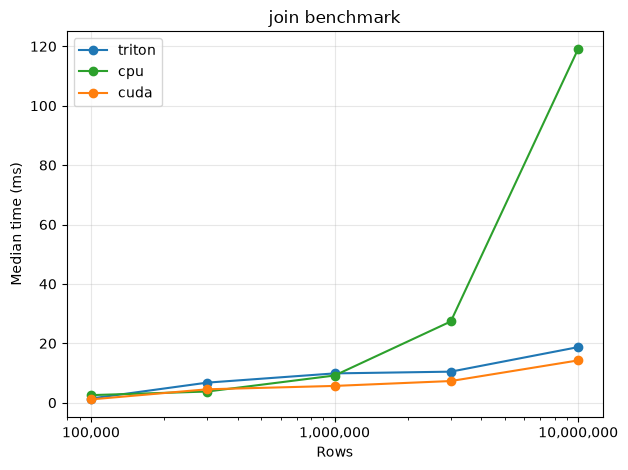

In [16]:
plot(join_results, "join benchmark")

## Distinct benchmark

Distinct benchmarks the native operation on one repeated integer key. Input preparation and result validation are outside the timed call.

In [4]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices
sizes = (200_000, 600_000, 2_000_000, 6_000_000, 12_000_000, 20_000_000)
distinct_cases = {}
distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST
for num_rows in sizes:
    num_unique = max(1, num_rows // 10)
    values = np.arange(num_rows, dtype=np.int64) % num_unique
    cpu_frame = pl.DataFrame({"key": values})
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_key = column_cudf_to_triton(
        cudf_frame.column_map["key"], name="key", stream=cudf_stream
    )
    cudf_table = plc.Table([cudf_frame.column_map["key"].obj])
    cpu_operation = lambda frame=cpu_frame: frame.unique(maintain_order=False)
    cuda_operation = lambda table=cudf_table: plc.stream_compaction.stable_distinct(
        table,
        [0],
        distinct_keep,
        plc.types.NullEquality.EQUAL,
        plc.types.NanEquality.ALL_EQUAL,
        stream=cudf_stream,
    )
    triton_operation = lambda key=triton_key: distinct_triton_indices(
        [key],
        torch.argsort(key.obj, stable=True),
        distinct_keep,
    )

    distinct_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": num_unique,
    }
    print(f"{num_rows:,} rows, {num_unique:,} expected distinct values")

200,000 rows, 20,000 expected distinct values
600,000 rows, 60,000 expected distinct values
2,000,000 rows, 200,000 expected distinct values
6,000,000 rows, 600,000 expected distinct values
12,000,000 rows, 1,200,000 expected distinct values
20,000,000 rows, 2,000,000 expected distinct values


In [5]:
distinct_results = benchmark(
    distinct_cases, warmups=warmups, repeats=repeats, name="distinct"
)
distinct_results

completed distinct case: 200,000 rows
completed distinct case: 600,000 rows
completed distinct case: 2,000,000 rows
completed distinct case: 6,000,000 rows
completed distinct case: 12,000,000 rows
completed distinct case: 20,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""distinct""","""cpu""",200000,1.5599662,1.5242135,1.36815
"""distinct""","""cuda""",200000,1.373283,1.33504,1.276928
"""distinct""","""triton""",200000,0.956934,0.861184,0.77312
"""distinct""","""cpu""",600000,3.282219,3.207716,2.95664
"""distinct""","""cuda""",600000,2.988227,3.006832,2.755904
…,…,…,…,…,…
"""distinct""","""cuda""",12000000,14.977437,14.915152,14.370816
"""distinct""","""triton""",12000000,15.548186,15.524864,15.486048
"""distinct""","""cpu""",20000000,285.313724,284.185281,269.098961


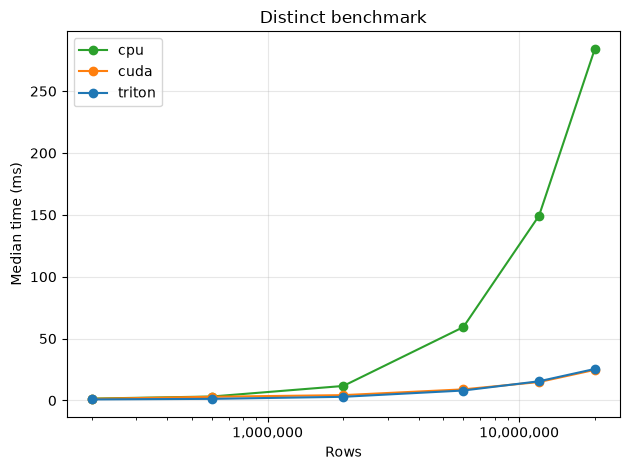

In [6]:
for num_rows, case in distinct_cases.items():
    assert case["cpu"]().height == case["expected_rows"]
    assert case["cuda"]().num_rows() == case["expected_rows"]
    assert case["triton"]().numel() == case["expected_rows"]

plot(distinct_results, "Distinct benchmark")

## Sort benchmark

Sort benchmarks a stable ascending sort of one integer key. The timed calls operate on prepared native inputs.

In [4]:
from cudf_polars.triton.triton_operations.sort_triton import sort_indices

sizes = (100_000, 300_000, 1_000_000, 3_000_000, 6_000_000, 10_000_000)
sort_cases = {}
sort_order = [plc.types.Order.ASCENDING]
sort_null_order = [plc.types.NullOrder.BEFORE]

for num_rows in sizes:
    rng = np.random.default_rng(42)
    values = rng.permutation(num_rows).astype(np.int64)
    cpu_frame = pl.DataFrame({"key": values})
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_key = column_cudf_to_triton(
        cudf_frame.column_map["key"], name="key", stream=cudf_stream
    )
    cudf_table = plc.Table([cudf_frame.column_map["key"].obj])

    cpu_operation = lambda frame=cpu_frame: frame.sort("key")
    cuda_operation = lambda table=cudf_table: plc.sorting.stable_sort_by_key(
        table, table, sort_order, sort_null_order, stream=cudf_stream
    )
    triton_operation = lambda key=triton_key: sort_indices(
        [key], sort_order, sort_null_order, torch.cuda.current_stream()
    )
    sort_cases[num_rows] = {
        "cpu": cpu_operation, "cuda": cuda_operation,
        "triton": triton_operation, "expected_rows": num_rows,
    }
    print(f"{num_rows:,} rows")

100,000 rows
300,000 rows
1,000,000 rows
3,000,000 rows
6,000,000 rows
10,000,000 rows


In [5]:
sort_results = benchmark(
    sort_cases, warmups=warmups, repeats=repeats, name="sort"
)
sort_results

completed sort case: 100,000 rows
completed sort case: 300,000 rows
completed sort case: 1,000,000 rows
completed sort case: 3,000,000 rows
completed sort case: 6,000,000 rows
completed sort case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""sort""","""cpu""",100000,0.896794,0.84525,0.640097
"""sort""","""cuda""",100000,1.648531,1.644896,1.37136
"""sort""","""triton""",100000,0.553622,0.56832,0.46592
"""sort""","""cpu""",300000,1.3901819,1.313544,1.145347
"""sort""","""cuda""",300000,2.495914,2.46976,2.350272
…,…,…,…,…,…
"""sort""","""cuda""",6000000,11.919658,11.969568,11.604832
"""sort""","""triton""",6000000,7.630406,7.552,7.522304
"""sort""","""cpu""",10000000,44.329616,42.72912,41.308479


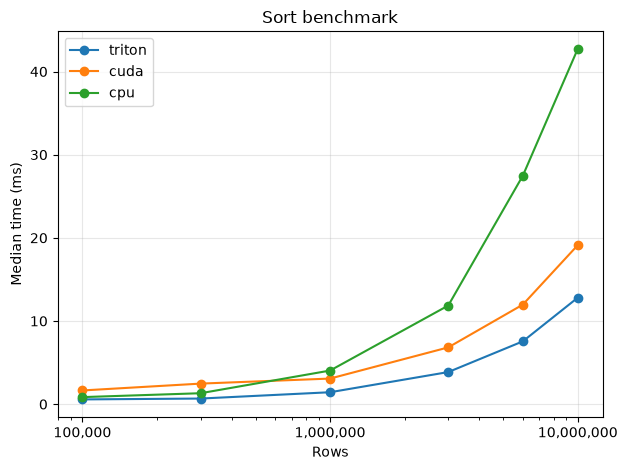

In [6]:
for num_rows, case in sort_cases.items():
    cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_result.num_rows() == case["expected_rows"]
    assert triton_result.numel() == case["expected_rows"]

plot(sort_results, "Sort benchmark")

## Groupby benchmark

Groupby benchmarks a `key -> sum(value)` aggregation using the prepared native inputs.


In [4]:
from cudf_polars.triton.components.base_triton import ExecutionContext, TritonCol, TritonNamedExpr
from cudf_polars.triton.triton_conversion import dataframe_cudf_to_triton
from cudf_polars.triton.components.agg_triton import TritonAgg
from cudf_polars.triton.ir_triton import groupby_triton

sizes = (100_000, 300_000, 1_000_000, 3_000_000, 6_000_000, 10_000_000)

groupby_cases = {}
groupby_key_dtype = torch.int64
groupby_value_dtype = torch.float32

groupby_agg = plc.aggregation.sum()

for num_rows in sizes:
    num_groups = max(1, num_rows // 100)
    rng = np.random.default_rng(42)
    values = {
        "key": np.arange(num_rows, dtype=np.int64) % num_groups,
        "value": rng.standard_normal(num_rows).astype(np.float32),
    }
    cpu_frame = pl.DataFrame(values)
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    triton_frame = dataframe_cudf_to_triton(cudf_frame)

    cudf_grouper = plc.groupby.GroupBy(
        plc.Table([cudf_frame.column_map["key"].obj]),
        null_handling=plc.types.NullPolicy.INCLUDE,
        keys_are_sorted=plc.types.Sorted.NO,
        column_order=[plc.types.Order.ASCENDING],
        null_precedence=[plc.types.NullOrder.BEFORE],
    )
    cudf_request = plc.groupby.GroupByRequest(
        cudf_frame.column_map["value"].obj, [groupby_agg]
    )

    triton_keys = (TritonNamedExpr("key", TritonCol(groupby_key_dtype, "key")),)
    triton_aggs = (
        TritonNamedExpr(
            "value_sum",
            TritonAgg(
                groupby_value_dtype,
                "sum",
                None,
                ExecutionContext.GROUPBY,
                TritonCol(groupby_value_dtype, "value"),
            ),
        ),
    )

    cpu_operation = lambda frame=cpu_frame: frame.group_by("key").agg(
        pl.col("value").sum().alias("value_sum")
    )
    cuda_operation = lambda grouper=cudf_grouper, request=cudf_request: grouper.aggregate(
        [request], stream=cudf_stream
    )
    triton_operation = lambda frame=triton_frame: groupby_triton(
        frame, triton_keys, triton_aggs, False, None
    )

    groupby_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": num_groups,
    }
    print(f"{num_rows:,} rows, {num_groups:,} expected groups")

100,000 rows, 1,000 expected groups
300,000 rows, 3,000 expected groups
1,000,000 rows, 10,000 expected groups
3,000,000 rows, 30,000 expected groups
6,000,000 rows, 60,000 expected groups
10,000,000 rows, 100,000 expected groups


In [5]:
groupby_results = benchmark(
    groupby_cases, warmups=warmups, repeats=repeats, name="groupby"
)
groupby_results

completed groupby case: 100,000 rows
completed groupby case: 300,000 rows
completed groupby case: 1,000,000 rows
completed groupby case: 3,000,000 rows
completed groupby case: 6,000,000 rows
completed groupby case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""groupby""","""cpu""",100000,1.3295019,1.306227,1.16737
"""groupby""","""cuda""",100000,1.096637,1.096064,0.919168
"""groupby""","""triton""",100000,1.928304,1.617376,1.548448
"""groupby""","""cpu""",300000,1.531138,1.54155,1.264011
"""groupby""","""cuda""",300000,2.45695,2.440336,2.307136
…,…,…,…,…,…
"""groupby""","""cuda""",6000000,8.291786,8.305808,8.171872
"""groupby""","""triton""",6000000,10.952739,10.78784,10.084992
"""groupby""","""cpu""",10000000,43.187938,42.837083,38.72696


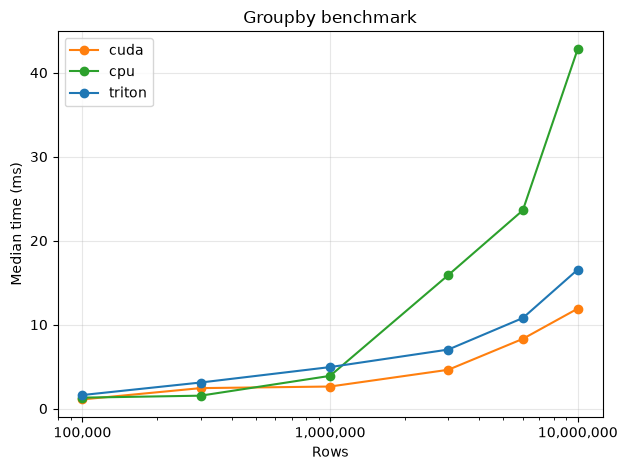

In [6]:
for num_rows, case in groupby_cases.items():
    cpu_result = case["cpu"]()
    cuda_keys, cuda_values = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    assert cpu_result.height == case["expected_rows"]
    assert cuda_keys.num_rows() == case["expected_rows"]
    assert cuda_values[0].num_rows() == case["expected_rows"]
    assert triton_result.num_rows == case["expected_rows"]

plot(groupby_results, "Groupby benchmark")

In [7]:
with pl.Config(tbl_rows=-1):
    groupby_results

shape: (18, 6)
┌───────────┬─────────┬──────────┬───────────┬───────────┬───────────┐
│ operation ┆ backend ┆ rows     ┆ mean_ms   ┆ median_ms ┆ min_ms    │
│ ---       ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---       │
│ str       ┆ str     ┆ i64      ┆ f64       ┆ f64       ┆ f64       │
╞═══════════╪═════════╪══════════╪═══════════╪═══════════╪═══════════╡
│ groupby   ┆ cpu     ┆ 100000   ┆ 1.3295019 ┆ 1.306227  ┆ 1.16737   │
│ groupby   ┆ cuda    ┆ 100000   ┆ 1.096637  ┆ 1.096064  ┆ 0.919168  │
│ groupby   ┆ triton  ┆ 100000   ┆ 1.928304  ┆ 1.617376  ┆ 1.548448  │
│ groupby   ┆ cpu     ┆ 300000   ┆ 1.531138  ┆ 1.54155   ┆ 1.264011  │
│ groupby   ┆ cuda    ┆ 300000   ┆ 2.45695   ┆ 2.440336  ┆ 2.307136  │
│ groupby   ┆ triton  ┆ 300000   ┆ 3.203216  ┆ 3.107296  ┆ 2.913408  │
│ groupby   ┆ cpu     ┆ 1000000  ┆ 4.035417  ┆ 3.900886  ┆ 3.305012  │
│ groupby   ┆ cuda    ┆ 1000000  ┆ 2.613712  ┆ 2.631168  ┆ 2.486272  │
│ groupby   ┆ triton  ┆ 1000000  ┆ 5.139098  ┆ 4.945792  ┆ 4.4